# Telecom Customer Churn Prediction - Model Training & Imbalance Optimization

This notebook implements the complete model training lifecycle for Telecom Customer Churn Prediction:
1. **Data Preprocessing**: Handling `TotalCharges`, missing value strategies for zero-tenure records, scaling, encoding.
2. **Feature Engineering**: Creating domain features (`AverageMonthlySpend`, `TenureGroup`, `ServiceCount`, `SecuritySupportCount`, etc.).
3. **Train-Test Split**: Stratified 80/20 split preserving the 26.54% churn rate with strict isolation of the test set.
4. **Training Six ML Algorithms**: Logistic Regression, Decision Tree, Random Forest, XGBoost, Gradient Boosting, and SVM.
5. **Class Imbalance Mitigation**: Comparing Baseline, Balanced Class Weights, and SMOTE oversampling via `imblearn` pipelines.
6. **Hyperparameter Tuning**: Stratified 5-Fold Cross-Validation on candidate models with balanced multi-metric model selection.


In [1]:
# 1. Imports, Environment Setup & Reproducibility
import os
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ML & Imbalance Libraries
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Add parent directory for module imports
sys.path.append(str(Path("..").resolve()))
from src.feature_engineering import TelecomFeatureEngineer, get_feature_column_types

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (8, 5)

print("Libraries and feature engineering module loaded successfully.")


Libraries and feature engineering module loaded successfully.


## Part 1: Data Preprocessing & Hygiene

### Handling Missing TotalCharges
In the raw Telco dataset, `TotalCharges` is an object data type containing 11 whitespace values (`' '`).
All 11 records have `tenure == 0`.
- **Domain Rationale**: Customers with zero tenure have just joined the telecom provider and have not yet accrued any monthly billing cycles.
- **Handling Strategy**: Converting `TotalCharges` to numeric and imputing `0.0` accurately reflects that their accrued historical billing total is zero.
- **Data Integrity**: No customer records are removed or altered in the raw dataset.


In [2]:
# Load Dataset
data_path = Path("../dataset/Telco-Customer-Churn.csv") if Path("../dataset/Telco-Customer-Churn.csv").exists() else Path("dataset/Telco-Customer-Churn.csv")
df = pd.read_csv(data_path)
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")

# Inspect the 11 zero-tenure records
zero_tenure = df[df['tenure'] == 0]
print(f"Records with tenure == 0: {len(zero_tenure)}")
zero_tenure[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'Churn']].head(11)


Dataset Shape: 7043 rows, 21 columns
Records with tenure == 0: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No


## Part 2: Feature Engineering

We create meaningful financial and service signals using our custom `TelecomFeatureEngineer`:
1. `AverageMonthlySpend`: `TotalCharges / tenure` (safely mapped to `MonthlyCharges` for `tenure == 0`).
2. `TenureGroup`: Discretized customer lifecycle into `New` (0–12 mo), `Medium` (13–36 mo), and `Long-term` (>36 mo).
3. `ServiceCount`: Total count of active telecommunication and internet services (1–9).
4. `SecuritySupportCount`: Sum of cybersecurity and technical support add-ons (`OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`).
5. `StreamingCount`: Count of entertainment streaming packages (`StreamingTV`, `StreamingMovies`).
6. `ContractPeriod_Months`: Numeric duration commitment (1 for Month-to-month, 12 for One year, 24 for Two year).
7. `MonthlyChargeDiff`: Difference between current monthly charge and historical average spend.


In [3]:
# Apply Feature Engineering
fe = TelecomFeatureEngineer()
df_fe = fe.transform(df)

engineered_cols = [
    'tenure', 'TenureGroup', 'TotalCharges', 'AverageMonthlySpend',
    'ServiceCount', 'SecuritySupportCount', 'StreamingCount',
    'ContractPeriod_Months', 'MonthlyChargeDiff'
]
print("Engineered Features Sample:")
df_fe[engineered_cols].head()


Engineered Features Sample:

,tenure,TenureGroup,TotalCharges,AverageMonthlySpend,ServiceCount,SecuritySupportCount,StreamingCount,ContractPeriod_Months,MonthlyChargeDiff
0,1,New,29.85,29.850000,2,1,0,1.0,0.000000
1,34,Medium,1889.50,55.573529,4,2,0,12.0,1.376471
2,2,New,108.15,54.075000,4,2,0,1.0,-0.225000
3,45,Long-term,1840.75,40.905556,4,3,0,12.0,1.394444
4,2,New,151.65,75.825000,2,0,0,1.0,-5.125000


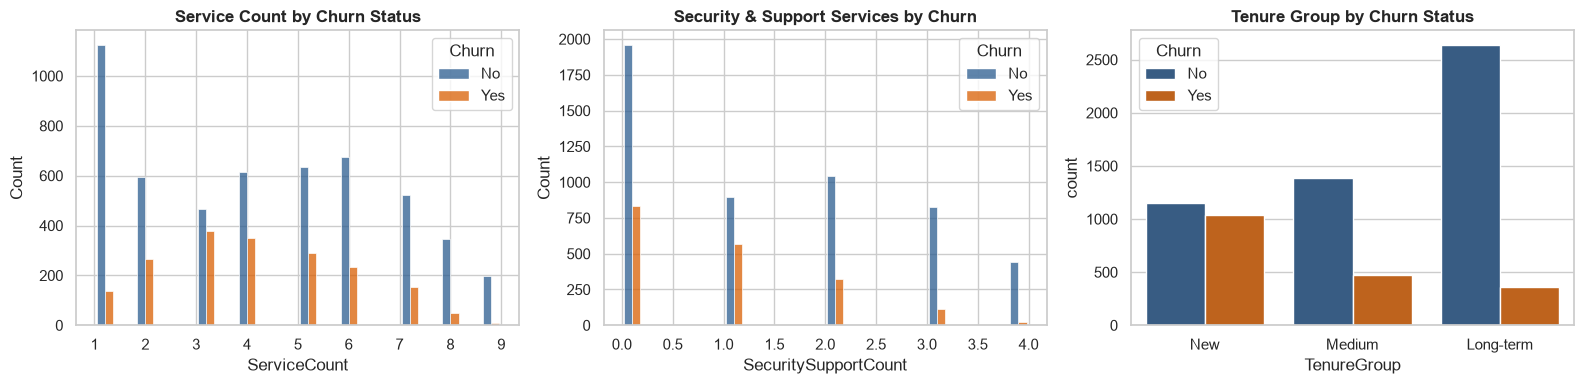

In [4]:
# Compare Original vs Engineered Features Distribution
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(data=df_fe, x='ServiceCount', hue='Churn', multiple='dodge', shrink=0.8, ax=axes[0], palette=['#2b5c8f', '#d95f02'])
axes[0].set_title("Service Count by Churn Status", fontweight='bold')

sns.histplot(data=df_fe, x='SecuritySupportCount', hue='Churn', multiple='dodge', shrink=0.8, ax=axes[1], palette=['#2b5c8f', '#d95f02'])
axes[1].set_title("Security & Support Services by Churn", fontweight='bold')

sns.countplot(data=df_fe, x='TenureGroup', hue='Churn', ax=axes[2], palette=['#2b5c8f', '#d95f02'])
axes[2].set_title("Tenure Group by Churn Status", fontweight='bold')

plt.tight_layout()
plt.show()


## Part 3: Stratified Train-Test Split (80/20)

To ensure realistic generalization without data leakage:
- **Split Ratio**: 80% Training (`5,634` rows), 20% Testing (`1,409` rows).
- **Stratification**: `stratify=y` preserves the ~26.54% churn prevalence across both subsets.
- **Reproducibility**: `random_state=42`.
- **Test Set Isolation**: The test set remains strictly unseen during preprocessing fitting, model training, and hyperparameter optimization.


In [5]:
# Separate Features and Target
X = df.drop(columns=['Churn'])
y = (df['Churn'].str.strip() == 'Yes').astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training Set Size: {len(X_train):,} ({len(X_train)/len(df):.1%}) | Churn Rate: {y_train.mean():.2%}")
print(f"Testing Set Size:  {len(X_test):,} ({len(X_test)/len(df):.1%}) | Churn Rate: {y_test.mean():.2%}")


Training Set Size: 5,634 (80.0%) | Churn Rate: 26.54%
Testing Set Size:  1,409 (20.0%) | Churn Rate: 26.54%


In [6]:
# Build Preprocessing Pipeline with ColumnTransformer
# Preprocessor is fitted ONLY on training data inside the pipeline
fe_train = fe.transform(X_train)
num_cols, cat_cols = get_feature_column_types(fe_train)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_cols)
    ]
)

print(f"Numerical Features ({len(num_cols)}): {num_cols}")
print(f"Categorical Features ({len(cat_cols)}): {cat_cols}")


Numerical Features (9): ['tenure', 'MonthlyCharges', 'TotalCharges', 'AverageMonthlySpend', 'ServiceCount', 'SecuritySupportCount', 'StreamingCount', 'ContractPeriod_Months', 'MonthlyChargeDiff']
Categorical Features (17): ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup']


## Part 4: Training Six Machine Learning Models (Baseline)

We train 6 distinct algorithms on the training data and evaluate their performance on the untouched test set:
1. **Logistic Regression** (Linear baseline)
2. **Decision Tree Classifier** (Non-linear rule-based baseline)
3. **Random Forest Classifier** (Bagged ensemble)
4. **XGBoost Classifier** (Gradient-boosted decision trees)
5. **Gradient Boosting Classifier** (Scikit-learn gradient boosting)
6. **Support Vector Machine (SVM)** (Maximum-margin classifier)


In [7]:
# Helper function to compute all 7 evaluation metrics
def evaluate_model(y_true, y_pred, y_prob=None):
    metrics = {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Balanced_Accuracy': balanced_accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1_Score': f1_score(y_true, y_pred, zero_division=0),
        'ROC_AUC': roc_auc_score(y_true, y_prob) if y_prob is not None else np.nan,
        'PR_AUC': average_precision_score(y_true, y_prob) if y_prob is not None else np.nan
    }
    return metrics

# Train Baseline Models
base_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'XGBoost': XGBClassifier(eval_metric='logloss', random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'Support Vector Machine': SVC(probability=True, random_state=42)
}

baseline_results = []
for name, clf in base_models.items():
    pipe = ImbPipeline([('fe', fe), ('preprocessor', preprocessor), ('clf', clf)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1] if hasattr(clf, 'predict_proba') else None
    res = evaluate_model(y_test, y_pred, y_prob)
    res['Model'] = name
    res['Strategy'] = 'Baseline'
    baseline_results.append(res)

df_baseline = pd.DataFrame(baseline_results)[['Model', 'Strategy', 'Accuracy', 'Balanced_Accuracy', 'Precision', 'Recall', 'F1_Score', 'ROC_AUC', 'PR_AUC']]
print("Baseline Models Performance Summary:")
display(df_baseline.sort_values(by='F1_Score', ascending=False).round(4))


Baseline Models Performance Summary:


,Model,Strategy,Accuracy,Balanced_Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC
0,Logistic Regression,Baseline,0.8006,0.7131,0.6545,0.5267,0.5837,0.8419,0.6338
4,Gradient Boosting,Baseline,0.8062,0.7110,0.6810,0.5080,0.5819,0.8429,0.6487
3,XGBoost,Baseline,0.7821,0.7014,0.6018,0.5294,0.5633,0.8209,0.5997
2,Random Forest,Baseline,0.7885,0.6947,0.6293,0.4947,0.5539,0.8275,0.6208
5,Support Vector Machine,Baseline,0.7956,0.6901,0.6641,0.4652,0.5472,0.7948,0.6167
1,Decision Tree,Baseline,0.7055,0.6194,0.4441,0.4358,0.4399,0.6188,0.3433


## Part 5: Handling Class Imbalance

With ~73.5% non-churn vs ~26.5% churn, baseline models prioritize majority class accuracy, resulting in lower churn recall.
We experiment with:
1. **Balanced Class Weights** (`class_weight='balanced'` / `scale_pos_weight` in XGBoost)
2. **Synthetic Minority Over-sampling Technique (SMOTE)** using `imbalanced-learn`

> [!IMPORTANT]
> SMOTE is enclosed strictly inside an `imblearn.pipeline.Pipeline`, ensuring that synthetic samples are generated **only on training folds**, never touching validation or test data!


In [8]:
# Train Models with Imbalance Mitigation Strategies
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
xgb_scale = neg_count / pos_count

imbalance_models = {
    'Logistic Regression': {
        'Balanced': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
        'SMOTE': LogisticRegression(max_iter=1000, random_state=42)
    },
    'Decision Tree': {
        'Balanced': DecisionTreeClassifier(class_weight='balanced', random_state=42),
        'SMOTE': DecisionTreeClassifier(random_state=42)
    },
    'Random Forest': {
        'Balanced': RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42),
        'SMOTE': RandomForestClassifier(n_estimators=100, random_state=42)
    },
    'XGBoost': {
        'Balanced': XGBClassifier(eval_metric='logloss', scale_pos_weight=xgb_scale, random_state=42),
        'SMOTE': XGBClassifier(eval_metric='logloss', random_state=42)
    },
    'Gradient Boosting': {
        'Balanced': GradientBoostingClassifier(random_state=42),
        'SMOTE': GradientBoostingClassifier(random_state=42)
    },
    'Support Vector Machine': {
        'Balanced': SVC(probability=True, class_weight='balanced', random_state=42),
        'SMOTE': SVC(probability=True, random_state=42)
    }
}

imbalance_results = []
for name, configs in imbalance_models.items():
    # 1. Balanced Weights
    pipe_bal = ImbPipeline([('fe', fe), ('preprocessor', preprocessor), ('clf', configs['Balanced'])])
    pipe_bal.fit(X_train, y_train)
    y_pred = pipe_bal.predict(X_test)
    y_prob = pipe_bal.predict_proba(X_test)[:, 1] if hasattr(configs['Balanced'], 'predict_proba') else None
    res_bal = evaluate_model(y_test, y_pred, y_prob)
    res_bal['Model'] = name
    res_bal['Strategy'] = 'Class_Weight_Balanced'
    imbalance_results.append(res_bal)

    # 2. SMOTE
    pipe_smote = ImbPipeline([
        ('fe', fe),
        ('preprocessor', preprocessor),
        ('smote', SMOTE(random_state=42)),
        ('clf', configs['SMOTE'])
    ])
    pipe_smote.fit(X_train, y_train)
    y_pred = pipe_smote.predict(X_test)
    y_prob = pipe_smote.predict_proba(X_test)[:, 1] if hasattr(configs['SMOTE'], 'predict_proba') else None
    res_smote = evaluate_model(y_test, y_pred, y_prob)
    res_smote['Model'] = name
    res_smote['Strategy'] = 'SMOTE'
    imbalance_results.append(res_smote)

df_imbal = pd.DataFrame(imbalance_results)[['Model', 'Strategy', 'Accuracy', 'Balanced_Accuracy', 'Precision', 'Recall', 'F1_Score', 'ROC_AUC', 'PR_AUC']]
print("Imbalance Mitigation Performance Summary:")
display(df_imbal.sort_values(by='F1_Score', ascending=False).round(4))


Imbalance Mitigation Performance Summary:


,Model,Strategy,Accuracy,Balanced_Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC
10,Support Vector Machine,Class_Weight_Balanced,0.7523,0.7640,0.5221,0.7888,0.6283,0.8282,0.6285
11,Support Vector Machine,SMOTE,0.7559,0.7544,0.5282,0.7513,0.6203,0.8245,0.6060
0,Logistic Regression,Class_Weight_Balanced,0.7353,0.7541,0.5008,0.7941,0.6143,0.8416,0.6323
1,Logistic Regression,SMOTE,0.7324,0.7504,0.4975,0.7888,0.6101,0.8389,0.6273
9,Gradient Boosting,SMOTE,0.7743,0.7303,0.5667,0.6364,0.5995,0.8402,0.6500
6,XGBoost,Class_Weight_Balanced,0.7615,0.7250,0.5426,0.6471,0.5902,0.8197,0.6089
4,Random Forest,Class_Weight_Balanced,0.7637,0.7213,0.5476,0.6310,0.5863,0.8285,0.6151
8,Gradient Boosting,Class_Weight_Balanced,0.8062,0.7110,0.6810,0.5080,0.5819,0.8429,0.6487
5,Random Forest,SMOTE,0.7771,0.7151,0.5798,0.5829,0.5813,0.8265,0.5996
7,XGBoost,SMOTE,0.7693,0.7047,0.5653,0.5668,0.5661,0.8193,0.6085


## Part 7: Hyperparameter Optimization & Model Selection

We select the 5 most promising model families and optimize their hyperparameters using:
- **Stratified 5-Fold Cross-Validation** (`StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`).
- **Optimization Metric**: `scoring='f1'` to directly optimize the balance between identifying churners (Recall) and minimizing false alarms (Precision).
- Models tuned: **Random Forest, XGBoost, Gradient Boosting, Logistic Regression, Support Vector Machine**.


In [9]:
# Hyperparameter Tuning with Stratified 5-Fold CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

tuning_configs = {
    'Random Forest': {
        'pipeline': ImbPipeline([('fe', fe), ('preprocessor', preprocessor), ('clf', RandomForestClassifier(random_state=42))]),
        'param_dist': {
            'clf__n_estimators': [100, 150, 200],
            'clf__max_depth': [6, 8, 10, None],
            'clf__min_samples_split': [2, 5, 10],
            'clf__min_samples_leaf': [1, 2, 4],
            'clf__class_weight': ['balanced', 'balanced_subsample']
        },
        'n_iter': 8
    },
    'XGBoost': {
        'pipeline': ImbPipeline([('fe', fe), ('preprocessor', preprocessor), ('clf', XGBClassifier(eval_metric='logloss', random_state=42))]),
        'param_dist': {
            'clf__n_estimators': [100, 150, 200],
            'clf__max_depth': [3, 4, 5],
            'clf__learning_rate': [0.03, 0.05, 0.1],
            'clf__subsample': [0.8, 1.0],
            'clf__colsample_bytree': [0.8, 1.0],
            'clf__scale_pos_weight': [1.5, 2.0, 2.77]
        },
        'n_iter': 8
    },
    'Gradient Boosting': {
        'pipeline': ImbPipeline([('fe', fe), ('preprocessor', preprocessor), ('smote', SMOTE(random_state=42)), ('clf', GradientBoostingClassifier(random_state=42))]),
        'param_dist': {
            'clf__n_estimators': [100, 150],
            'clf__learning_rate': [0.03, 0.05, 0.1],
            'clf__max_depth': [3, 4],
            'clf__subsample': [0.8, 1.0]
        },
        'n_iter': 6
    },
    'Logistic Regression': {
        'pipeline': ImbPipeline([('fe', fe), ('preprocessor', preprocessor), ('clf', LogisticRegression(max_iter=1000, random_state=42))]),
        'param_dist': {
            'clf__C': [0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0],
            'clf__penalty': ['l2'],
            'clf__class_weight': ['balanced', None]
        },
        'n_iter': 7
    },
    'Support Vector Machine': {
        'pipeline': ImbPipeline([('fe', fe), ('preprocessor', preprocessor), ('clf', SVC(probability=True, random_state=42))]),
        'param_dist': {
            'clf__C': [0.5, 1.0, 2.0],
            'clf__kernel': ['rbf'],
            'clf__class_weight': ['balanced', None]
        },
        'n_iter': 3
    }
}

tuned_results = []
tuned_pipes = {}

for name, cfg in tuning_configs.items():
    search = RandomizedSearchCV(
        estimator=cfg['pipeline'],
        param_distributions=cfg['param_dist'],
        n_iter=cfg['n_iter'],
        scoring='f1',
        cv=cv,
        random_state=42,
        n_jobs=-1
    )
    search.fit(X_train, y_train)
    best_pipe = search.best_estimator_
    y_pred = best_pipe.predict(X_test)
    y_prob = best_pipe.predict_proba(X_test)[:, 1] if hasattr(best_pipe.named_steps['clf'], 'predict_proba') else None
    
    m = evaluate_model(y_test, y_pred, y_prob)
    m['Model'] = f"{name} (Tuned)"
    m['Strategy'] = 'Hyperparameter_Tuned'
    m['CV_F1_Score'] = search.best_score_
    tuned_results.append(m)
    tuned_pipes[name] = best_pipe

df_tuned = pd.DataFrame(tuned_results)[['Model', 'Strategy', 'Accuracy', 'Balanced_Accuracy', 'Precision', 'Recall', 'F1_Score', 'ROC_AUC', 'PR_AUC', 'CV_F1_Score']]
print("Tuned Models Performance Summary:")
display(df_tuned.sort_values(by='F1_Score', ascending=False).round(4))


Tuned Models Performance Summary:


,Model,Strategy,Accuracy,Balanced_Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,CV_F1_Score
0,Random Forest (Tuned),Hyperparameter_Tuned,0.7743,0.7678,0.5551,0.7540,0.6395,0.8435,0.6514,0.6348
1,XGBoost (Tuned),Hyperparameter_Tuned,0.7672,0.7621,0.5446,0.7513,0.6315,0.8456,0.6567,0.6341
4,Support Vector Machine (Tuned),Hyperparameter_Tuned,0.7466,0.7618,0.5147,0.7941,0.6246,0.8307,0.6358,0.6230
2,Gradient Boosting (Tuned),Hyperparameter_Tuned,0.7686,0.7469,0.5504,0.7005,0.6165,0.8410,0.6427,0.6342
3,Logistic Regression (Tuned),Hyperparameter_Tuned,0.7367,0.7550,0.5025,0.7941,0.6155,0.8407,0.6274,0.6302


## Multi-Metric Model Selection

To avoid selecting a model based on raw accuracy alone (which is misleading under class imbalance), we use a balanced composite score:

$$\text{Composite Score} = 0.30 \times \text{F1} + 0.25 \times \text{PR-AUC} + 0.20 \times \text{ROC-AUC} + 0.15 \times \text{Recall} + 0.10 \times \text{Accuracy}$$


In [10]:
# Aggregate All Models and Rank by Composite Score
df_all = pd.concat([df_baseline, df_imbal, df_tuned], ignore_index=True)
df_all['Composite_Score'] = (
    0.30 * df_all['F1_Score'] +
    0.25 * df_all['PR_AUC'] +
    0.20 * df_all['ROC_AUC'] +
    0.15 * df_all['Recall'] +
    0.10 * df_all['Accuracy']
)

ranked = df_all.sort_values(by='Composite_Score', ascending=False).reset_index(drop=True)
print("Top 10 Models Ranked by Composite Score:")
display(ranked.head(10).round(4))

best_model_name = ranked.iloc[0]['Model']
best_strategy = ranked.iloc[0]['Strategy']
print(f"\nWinning Model: {best_model_name} [{best_strategy}]")


Top 10 Models Ranked by Composite Score:


,Model,Strategy,Accuracy,Balanced_Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,CV_F1_Score,Composite_Score
0,Random Forest (Tuned),Hyperparameter_Tuned,0.7743,0.7678,0.5551,0.7540,0.6395,0.8435,0.6514,0.6348,0.7139
1,XGBoost (Tuned),Hyperparameter_Tuned,0.7672,0.7621,0.5446,0.7513,0.6315,0.8456,0.6567,0.6341,0.7122
2,Support Vector Machine (Tuned),Hyperparameter_Tuned,0.7466,0.7618,0.5147,0.7941,0.6246,0.8307,0.6358,0.6230,0.7063
3,Support Vector Machine,Class_Weight_Balanced,0.7523,0.7640,0.5221,0.7888,0.6283,0.8282,0.6285,NaN,0.7048
4,Logistic Regression,Class_Weight_Balanced,0.7353,0.7541,0.5008,0.7941,0.6143,0.8416,0.6323,NaN,0.7033
5,Logistic Regression (Tuned),Hyperparameter_Tuned,0.7367,0.7550,0.5025,0.7941,0.6155,0.8407,0.6274,0.6302,0.7024
6,Logistic Regression,SMOTE,0.7324,0.7504,0.4975,0.7888,0.6101,0.8389,0.6273,NaN,0.6992
7,Gradient Boosting (Tuned),Hyperparameter_Tuned,0.7686,0.7469,0.5504,0.7005,0.6165,0.8410,0.6427,0.6342,0.6957
8,Support Vector Machine,SMOTE,0.7559,0.7544,0.5282,0.7513,0.6203,0.8245,0.6060,NaN,0.6908
9,Gradient Boosting,SMOTE,0.7743,0.7303,0.5667,0.6364,0.5995,0.8402,0.6500,NaN,0.6833



Winning Model: Random Forest (Tuned) [Hyperparameter_Tuned]
